Epoch 1/3, Loss: 0.5700
Epoch 2/3, Loss: 0.3510
Epoch 3/3, Loss: 0.3020


/tmp/ipykernel_1049/4064458866.py:115: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared = prepare(qmodel, inplace=False)
/tmp/ipykernel_1049/4064458866.py:127: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dyna


INT8 Quantization completed!

========== MODEL COMPRESSION RESULTS ==========
                  Metric  Original FP32  Quantized INT8
         Model Size (MB)          0.793           0.209
            Accuracy (%)         87.210          87.410
Inference Time (seconds)          2.807           2.872

Model Size Reduction: 73.66 %
Accuracy Difference: -0.2 percentage points


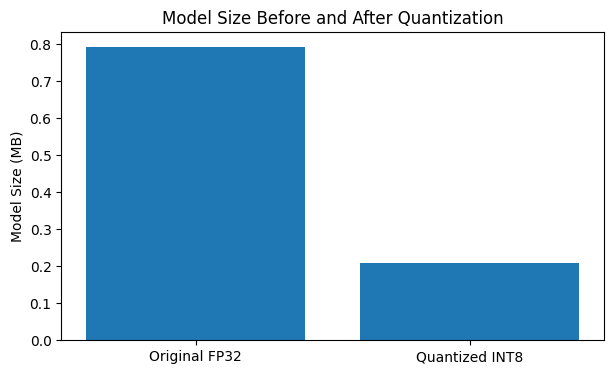


Experiment Completed Successfully!


In [6]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import copy, os, time
import pandas as pd

from torch.utils.data import DataLoader
from torch.ao.quantization import (
    QuantStub, DeQuantStub, get_default_qconfig,
    prepare, convert, fuse_modules)

# 1. Load Fashion-MNIST dataset
train_data = torchvision.datasets.FashionMNIST(
    "./data", train=True, download=True,
    transform=transforms.ToTensor())

test_data = torchvision.datasets.FashionMNIST(
    "./data", train=False, download=True,
    transform=transforms.ToTensor())

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128)

# 2. Define CNN model
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.quant = QuantStub()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)

        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)

        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)
        self.dequant = DeQuantStub()

    def forward(self, x):
        x = self.quant(x)
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)
        return self.dequant(x)

# 3. Train original FP32 model
model = CNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(3):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}/3, Loss: {total_loss/len(train_loader):.4f}")

# 4. Evaluation function
def evaluate(model):
    model.eval()
    correct, total = 0, 0
    start = time.time()

    with torch.no_grad():
        for images, labels in test_loader:
            predicted = model(images).argmax(1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total, time.time() - start
original_acc, original_time = evaluate(model)

# 5. Save original model size
model = model.cpu().eval()
torch.save(model.state_dict(), "original.pth")
original_size = os.path.getsize("original.pth") / (1024**2)

# 6. Apply INT8 quantization
backend = "x86" if "x86" in torch.backends.quantized.supported_engines else "fbgemm"
torch.backends.quantized.engine = backend

qmodel = copy.deepcopy(model)

# Fuse layers
fuse_modules(qmodel, [
    ["conv1", "relu1"],
    ["conv2", "relu2"],
    ["fc1", "relu3"]
], inplace=True)

qmodel.qconfig = get_default_qconfig(backend)

# Prepare quantization
prepared = prepare(qmodel, inplace=False)

# 7. Calibration
prepared.eval()

with torch.no_grad():
    for i, (images, _) in enumerate(train_loader):
        prepared(images)
        if i == 19:
            break

# 8. Convert FP32 to INT8
qmodel = convert(prepared, inplace=False)

print("\nINT8 Quantization completed!")

# 9. Evaluate quantized model
quant_acc, quant_time = evaluate(qmodel)

# 10. Calculate quantized model size
torch.save(qmodel.state_dict(), "quantized.pth")
quant_size = os.path.getsize("quantized.pth") / (1024**2)

reduction = ((original_size - quant_size) / original_size) * 100

# 11. Display comparison
results = pd.DataFrame({
    "Metric": [
        "Model Size (MB)",
        "Accuracy (%)",
        "Inference Time (seconds)"
    ],
    "Original FP32": [
        original_size, original_acc, original_time
    ],
    "Quantized INT8": [
        quant_size, quant_acc, quant_time
    ]
})

print("\n========== MODEL COMPRESSION RESULTS ==========")
print(results.round(3).to_string(index=False))

print("\nModel Size Reduction:", round(reduction, 2), "%")
print("Accuracy Difference:", round(original_acc - quant_acc, 2), "percentage points")

# 12. Visualize model size comparison
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.bar(
    ["Original FP32", "Quantized INT8"],
    [original_size, quant_size]
)
plt.title("Model Size Before and After Quantization")
plt.ylabel("Model Size (MB)")
plt.show()

print("\nExperiment Completed Successfully!")